In [ ]:
#Ej 2
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

In [3]:
# Dataset de desarrollo (Iris)
iris_df = pd.read_csv('IRIS.csv')

# Dataset de la flor secreta
secret_flower_df = pd.read_csv('secret_flower.csv')

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


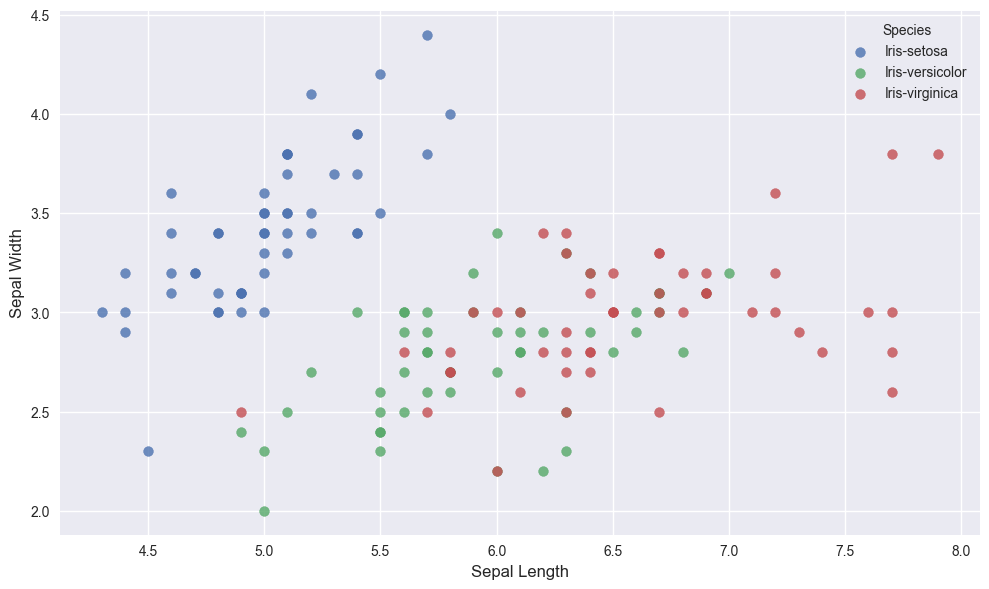

In [4]:
# Un vistazo rápido
display(iris_df.head())
print(iris_df['species'].value_counts())
display(iris_df.describe())

# Scatter: sepal_length vs sepal_width
plt.style.use('seaborn-v0_8')
plt.figure(figsize=(10, 6))

for especie, grupo in iris_df.groupby("species"):
    plt.scatter(
        grupo["sepal_length"],
        grupo["sepal_width"],
        label=especie,
        s=50,
        alpha=0.8
    )

plt.xlabel("Sepal Length", fontsize=12)
plt.ylabel("Sepal Width",  fontsize=12)
plt.legend(title="Species", loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
# Separar características/target
X = iris_df.drop("species", axis=1)
y = iris_df["species"]

# Modelos y sus grillas
models_param_grid = {
    "KNN": {
        "model": Pipeline([
            ("scaler", StandardScaler()),
            ("knn", KNeighborsClassifier())
        ]),
        "params": {
            "knn__n_neighbors": [3, 5, 7, 9],
            "knn__weights": ["uniform", "distance"],
            "knn__metric": ["minkowski"],
        }
    },
    "DecisionTree": {
        "model": DecisionTreeClassifier(random_state=42),
        "params": {
            "max_depth": [None, 3, 5, 10],
            "min_samples_split": [2, 5],
            "criterion": ["gini", "entropy"]
        }
    },
    "RandomForest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "n_estimators": [50, 100],
            "max_depth": [None, 5, 10],
            "min_samples_split": [2, 5],
            "criterion": ["gini", "entropy"]
        }
    }
}

# GridSearchCV
results = {}
for name, mp in models_param_grid.items():
    gs = GridSearchCV(
        estimator=mp["model"],
        param_grid=mp["params"],
        cv=3,
        scoring="accuracy",
        n_jobs=-1
    )
    gs.fit(X, y)
    results[name] = {
        "best_score": gs.best_score_,
        "best_params": gs.best_params_
    }

# Mostrar resultados
for name, res in results.items():
    print(f"{name}:")
    print(f"  Mejor score (cv=3): {res['best_score']:.4f}")
    print(f"  Mejores parámetros: {res['best_params']}")
    print()

best_name = max(results, key=lambda k: results[k]["best_score"])

print(f"Modelo ganador: {best_name}")
print(f"Accuracy CV-3: {results[best_name]['best_score']:.4f}")


KNN:
  Mejor score (cv=3): 0.9733
  Mejores parámetros: {'knn__metric': 'minkowski', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}

DecisionTree:
  Mejor score (cv=3): 0.9733
  Mejores parámetros: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}

RandomForest:
  Mejor score (cv=3): 0.9667
  Mejores parámetros: {'criterion': 'gini', 'max_depth': None, 'min_samples_split': 2, 'n_estimators': 50}

Modelo ganador: KNN
Accuracy CV-3: 0.9733


Accuracy promedio (3-fold CV): 0.9800
Predicción de la flor híbrida: Iris-virginica


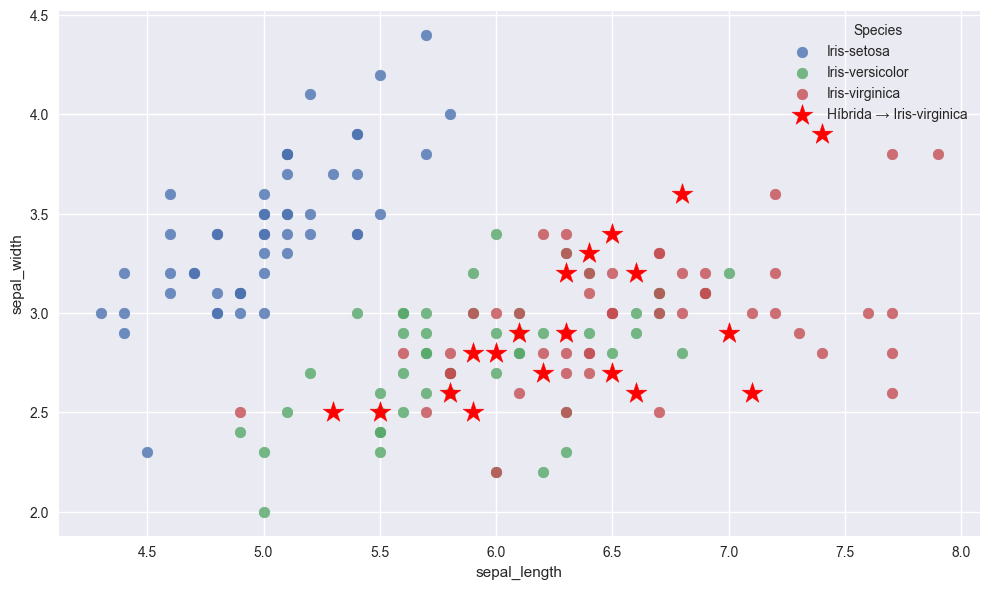

In [6]:
# tomamos KNN, fue el elegido con k=5, weights='uniform'
best_model = KNeighborsClassifier(n_neighbors=5, weights='uniform')

# Accuracy promedio en CV-3
scores = cross_val_score(best_model, X, y, cv=3, scoring='accuracy')
print(f"Accuracy promedio (3-fold CV): {scores.mean():.4f}")

# Entrenar sobre todo el iris
best_model.fit(X, y)

# Preparar la flor secreta (mismas columnas que X)
flower_X = secret_flower_df.drop(columns=["species"], errors="ignore")
flower_X = flower_X[X.columns]

# Predecir
pred = best_model.predict(flower_X)[0]
print(f"Predicción de la flor híbrida: {pred}")

# Scatter final con la híbrida destacada
feat_x, feat_y = "sepal_length", "sepal_width"
plt.figure(figsize=(10, 6))
plt.style.use("seaborn-v0_8")

for especie, grupo in iris_df.groupby("species"):
    plt.scatter(
        grupo[feat_x],
        grupo[feat_y],
        label=especie,
        s=60,
        alpha=0.8
    )

plt.scatter(
    flower_X[feat_x],
    flower_X[feat_y],
    marker="*",
    s=250,
    c="red",
    label=f"Híbrida → {pred}"
)

plt.xlabel(feat_x)
plt.ylabel(feat_y)
plt.legend(title="Species", loc="upper right")
plt.tight_layout()
plt.show()


In [ ]:
# centroide híbrida
centro_hibrida = flower_X.mean()

# centroide por especie
centroides = iris_df.groupby("species")[X.columns].mean()

sims = cosine_similarity(
    centroides.values,
    centro_hibrida.values.reshape(1, -1)
).ravel()

similaridad = pd.Series(sims, index=centroides.index).sort_values(ascending=False)
print("Similaridad coseno (↑ más parecido):")
display(similaridad)

Similaridad coseno (↑ más parecido):


species
Iris-virginica     0.999490
Iris-versicolor    0.998124
Iris-setosa        0.901906
dtype: float64